# VeridisQuo Model Exploration

This notebook demonstrates how to load and explore the DeepFakeDetector model using the project's modules.

## 1. Environment Setup

Add the `src/` directory to PYTHONPATH to import project modules.

In [1]:
import sys
from pathlib import Path

# Add src/ directory to PYTHONPATH
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = project_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

print(f"Project root: {project_root}")
print(f"Src path: {src_path}")
print(f"Python path: {sys.path[:3]}")

Project root: /Users/theogenial/Documents/repo/VeridisQuo
Src path: /Users/theogenial/Documents/repo/VeridisQuo/src
Python path: ['/Users/theogenial/Documents/repo/VeridisQuo/src', '/Users/theogenial/.local/share/uv/python/cpython-3.13.5-macos-aarch64-none/lib/python313.zip', '/Users/theogenial/.local/share/uv/python/cpython-3.13.5-macos-aarch64-none/lib/python3.13']


## 2. Import Project Modules

In [2]:
import torch
import logging
from io import StringIO
from torchsummary import summary

# Imports from VeridisQuo project
from utils.load_model import load_model
from utils.device import get_device
from config import DEEPFAKE_DETECTION_MODEL_PATH

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

## 3. Load Model

In [3]:
# Detect device (CPU or CUDA)
device = get_device()
print(f"Using device: {device}")

# Load model
model = load_model(DEEPFAKE_DETECTION_MODEL_PATH, device=device, eval_mode=True)
model.to(device)
print("✓ Model loaded successfully")

⚠ GPU not available, using CPU
Using device: cpu


2025-12-30 10:13:59,742 - frequal/torch_dct_extractor.py - INFO - TorchDCTExtractor initialized successfully.
2025-12-30 10:13:59,743 - frequal/torch_fft_extractor.py - INFO - TorchFFTExtractor initialized successfully.
2025-12-30 10:13:59,771 - frequal.FusionMLP - INFO - FusionMLP weights initialized with Kaiming initialization
2025-12-30 10:13:59,771 - frequal.FusionMLP - INFO - FusionMLP initialized: 1024 -> [1024, 512] -> 1024
2025-12-30 10:13:59,773 - frequal.FrequencyFeatureExtractor - INFO - DCT/FFT projections initialized with Xavier initialization
2025-12-30 10:13:59,773 - frequal.FrequencyFeatureExtractor - INFO - FrequencyFeatureExtractor initialized successfully.
2025-12-30 10:13:59,773 - classification.FaceFeaturesConcatenator - INFO - LayerNorm weights initialized
2025-12-30 10:13:59,774 - classification.FaceFeaturesConcatenator - INFO - FaceFeaturesConcatenator initialized: spatial_dim=1792, frequency_dim=1024, output_dim=2816
2025-12-30 10:13:59,823 - classification/fac

✓ Model loaded successfully


## 4. Inference Test with Random Input

In [4]:
# Create random input (batch_size=1, channels=3, height=224, width=224)
random_input = torch.randn(1, 3, 224, 224).to(device)
print(f"Input shape: {random_input.shape}")

# Make prediction
with torch.no_grad():
    output = model(random_input)
    
print(f"Output shape: {output.shape}")
print(f"Output logits: {output}")
print(f"Predicted class: {output.argmax(dim=1).item()} ({'FAKE' if output.argmax(dim=1).item() == 0 else 'REAL'})")

Input shape: torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 2])
Output logits: tensor([[-16.2920, -16.3909]])
Predicted class: 0 (FAKE)


## 5. Model Parameters Exploration

In [5]:
# Count parameters by module
total_params = 0
module_params = {}

for name, param in model.named_parameters():
    module_name = name.split('.')[0]
    num_params = param.numel()
    total_params += num_params
    
    if module_name not in module_params:
        module_params[module_name] = 0
    module_params[module_name] += num_params

print(f"Total parameters: {total_params:,}")
print("\nParameters by module:")
for module, count in sorted(module_params.items(), key=lambda x: x[1], reverse=True):
    print(f"  {module:30s}: {count:12,} ({count/total_params*100:5.2f}%)")

Total parameters: 25,048,114

Parameters by module:
  efficient                     :   19,341,616 (77.22%)
  classifier                    :    3,544,834 (14.15%)
  frequal_extractor             :    2,156,032 ( 8.61%)
  concatenator                  :        5,632 ( 0.02%)


## Load Dataset and Make Real Predictions

In [6]:
# Example: load and test on real data
from data.dataset import FaceDataset
from data.dataloader import DataLoaderWrapper

# Load evaluation dataset
eval_csv = project_root / "data" / "preprocessed_dataset" / "eval.csv"

if eval_csv.exists():
    eval_dataset = FaceDataset(str(eval_csv))
    eval_loader = DataLoaderWrapper(
        eval_dataset,
        batch_size=2,
        shuffle=False,
        device=device
    )
    
    # Get a batch
    batch = next(iter(eval_loader))
    images, labels = batch
    
    print(f"Batch images shape: {images.shape}")
    print(f"Batch labels shape: {labels.shape}")
    print(f"Labels: {labels}")
    
    # Make predictions
    with torch.no_grad():
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
    
    print(f"Predictions: {predictions}")
    print(f"Accuracy on this batch: {(predictions == labels).float().mean().item():.2%}")

## 10. Mosaic Batch

In [8]:
# Load and test on real data
from data.dataset import FaceDataset
from data.dataloader import DataLoaderWrapper
import matplotlib.pyplot as plt
import numpy as np


eval_csv = project_root / "data" / "preprocessed_dataset" / "eval.csv"


eval_dataset = FaceDataset(str(eval_csv))
eval_loader = DataLoaderWrapper(
    eval_dataset,
    batch_size=9,
    shuffle=False,
    device=device
)
    
# Get a batch
batch = next(iter(eval_loader))
images, labels = batch

print(f"Batch images shape: {images.shape}")
print(f"Batch labels shape: {labels.shape}")
print(f"Labels: {labels}")

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

2025-12-30 10:23:26,956 - data.FaceDataset - INFO - Loaded 108853 samples from eval.csv (augment=False)
2025-12-30 10:23:26,957 - data.DataLoaderWrapper - INFO - DataLoaderWrapper initialized: 108853 samples, 12095 batches, device=cpu


Batch images shape: torch.Size([9, 3, 224, 224])
Batch labels shape: torch.Size([9])
Labels: tensor([0, 1, 0, 1, 1, 1, 0, 1, 0])


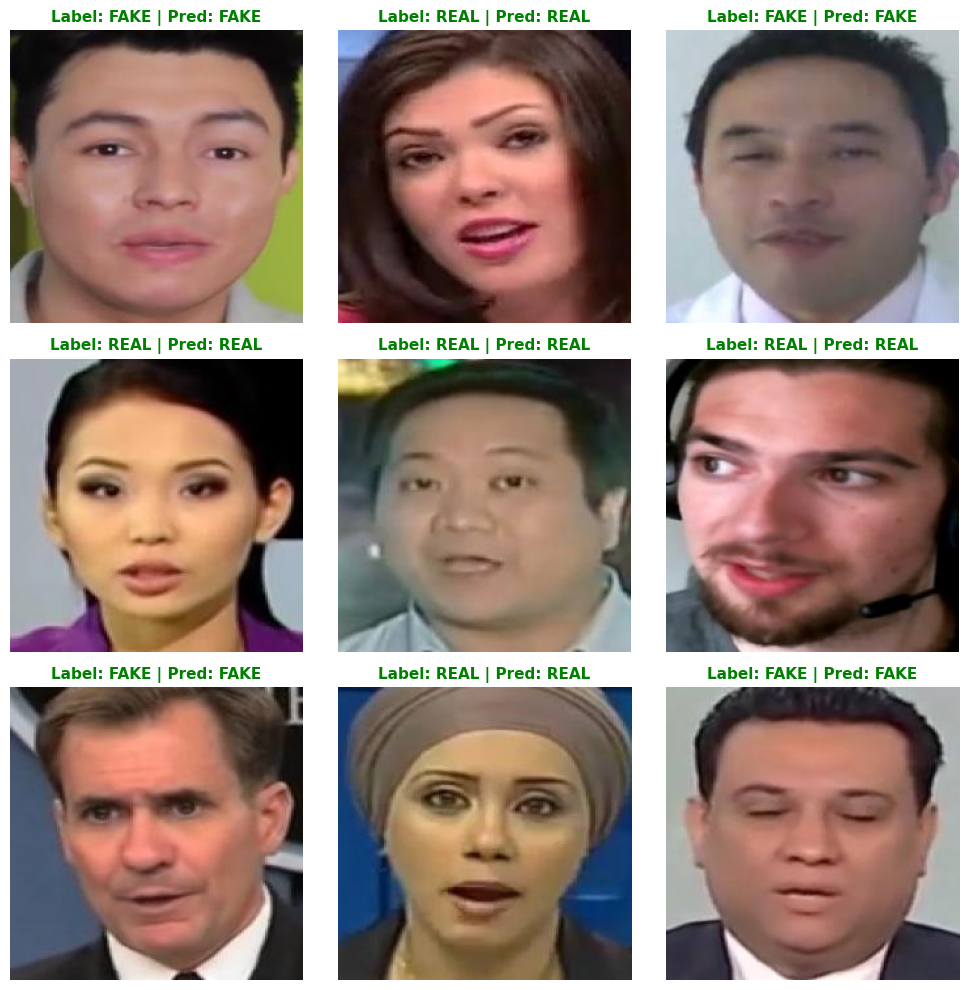

In [9]:
from utils.image import denormalize_image


# Create mosaic
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

label_names = {0: "FAKE", 1: "REAL"}
colors = {True: "green", False: "red"}  

for i in range(min(9, len(images))):
    ax = axes[i]
    
    # Denormalize and display image
    img = denormalize_image(images[i])
    ax.imshow(img)
    
    # Prepare title
    true_label = labels[i].item()
    pred_label = predictions[i].item()
    is_correct = true_label == pred_label
    
    title = f"Label: {label_names[true_label]} | Pred: {label_names[pred_label]}"
    title_color = colors[is_correct]
    
    ax.set_title(title, fontsize=11, fontweight='bold', color=title_color)
    ax.axis('off')

for i in range(len(images), 9):
    axes[i].axis('off')

plt.tight_layout()
plt.show()


## GradCAM Visualization: Important Regions for Prediction

GradCAM (Gradient-weighted Class Activation Mapping) visualizes which regions of the image are important for the model's decision.

This visualization shows:
- **Original Image**: The input image
- **Heatmap**: Activation map (red = important regions, blue = less important regions)
- **Overlay**: Heatmap superimposed on the original image

Image 0:
  True label: FAKE
  Predicted: FAKE
  Correct: ✓


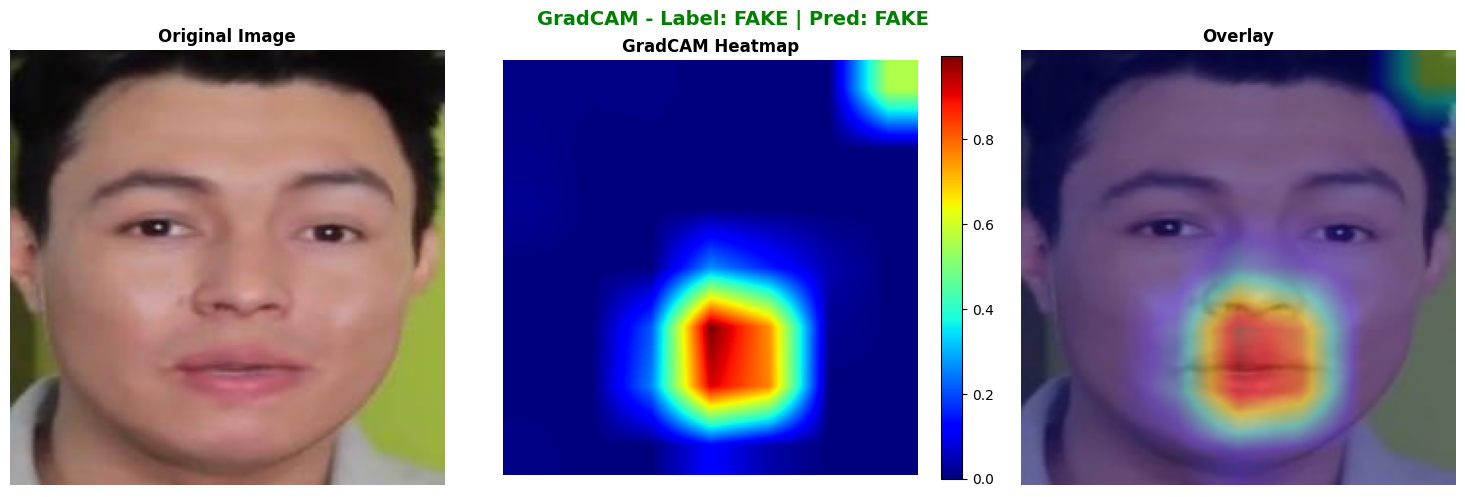

In [10]:
from gradcam.gradcam import GradCAM, GradCAMVisualizer

# Select an image from the batch (index 0)
img_index = 0
single_image = images[img_index:img_index+1]  # Keep batch dimension [1, 3, 224, 224]
true_label = labels[img_index].item()
pred_label = predictions[img_index].item()

print(f"Image {img_index}:")
print(f"  True label: {label_names[true_label]}")
print(f"  Predicted: {label_names[pred_label]}")
print(f"  Correct: {'✓' if true_label == pred_label else '✗'}")

# Initialize GradCAM on the last convolutional layer of EfficientNet
target_layer = model.efficient.features[-1]
gradcam = GradCAM(model, target_layer)

# Generate GradCAM heatmap
cam = gradcam(
    single_image, 
    target_class=pred_label,  # Visualize for predicted class
    upsample_to=(224, 224)    # Resize to image size
)

# Create visualization
overlay = GradCAMVisualizer.create_visualization(
    original_image=single_image[0],
    cam=cam[0],
    alpha=0.4,
    denormalize=True
)

# Side-by-side display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original image
img_original = denormalize_image(single_image[0])
axes[0].imshow(img_original)
axes[0].set_title('Original Image', fontsize=12, fontweight='bold')
axes[0].axis('off')

# Heatmap only
cam_np = cam[0].cpu().numpy()
im = axes[1].imshow(cam_np, cmap='jet')
axes[1].set_title('GradCAM Heatmap', fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046)

# Overlay
axes[2].imshow(overlay)
axes[2].set_title('Overlay', fontsize=12, fontweight='bold')
axes[2].axis('off')

# Global title
title_color = 'green' if true_label == pred_label else 'red'
fig.suptitle(
    f'GradCAM - Label: {label_names[true_label]} | Pred: {label_names[pred_label]}',
    fontsize=14,
    fontweight='bold',
    color=title_color
)

plt.tight_layout()
plt.show()

